<div align="center">

<h2><strong>PEMBUATAN RECIPE UNTUK SIMULASI GELOMBANG SEISMIK SINTETIS (SYNTHETIC SEISMIC-WAVE REFERENCE IMPLEMENTATION)</strong></h2>
<h3><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h3>


<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<h5><strong> Oleh:</strong></h5>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li>
    <strong>YUNI</strong>
    <div style="margin-top:10px;">
      <strong>H061241072</strong>
    </div>
  </li>
</ul>

<p><strong>DEPARTEMEN GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong></strong></p>
<p><strong></strong></p>
<p><strong>2026</strong></p>

</div>

## **STUDI KASUS**
**Haris, A., Sandrina, R., & Riyanto, A. (2018).** *Integrated AVO, Elastic Seismic Inversion and Petrophysical Analysis for Reservoir Characterization: A Case Study of Gas Field, South Sumatera Basin.* Spektra: Jurnal Fisika dan Aplikasinya, 3(1), 7-14. DOI: 10.21009/SPEKTRA.031.02  

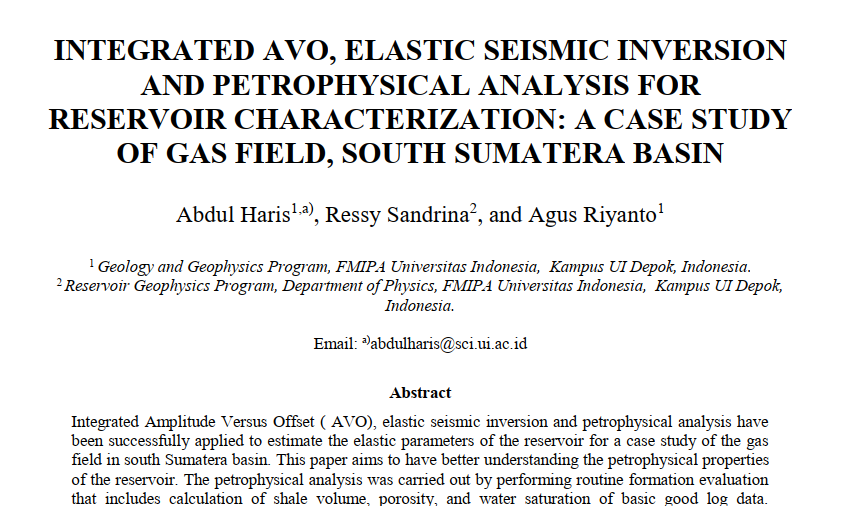  

Studi kasus berfokus pada **Formasi Talang Akar, Cekungan Sumatera Selatan**, yaitu cekungan busur belakang (back-arc) berumur Tersier yang tersusun atas sedimen delta plain berupa serpih, lanau, batupasir kuarsa, serpih karbonan, batubara, dan sebagian konglomerat. Parameter kunci dari jurnal yang dijadikan acuan model sintetik:

| Parameter | Nilai pada jurnal |
|---|---|
| P-impedance reservoar | 9000 - 10000 (m/s)*(g/cc) |
| S-impedance reservoar | 5000 - 5600 (m/s)*(g/cc) |
| Densitas reservoar | 2.25 - 2.45 g/cc (hingga 2.6 g/cc) |
| Cutoff Vsh / porositas pasir | 34 % / > 15 % |
| Sw zona hidrokarbon (LMR) | < 65 % |
| Vs | Castagna's mudrock line |
| Respon AVO | Intercept (A) positif, Gradient (B) negatif -> Type I (Rutherford-Williams) / Type -1 non-conforming sand (Young-Lo Piccolo) |


Pada lapangan gas Cekungan Sumatera Selatan, identifikasi batupasir reservoar bersaturasi gas tidak dapat mengandalkan penampang seismik post-stack konvensional saja. Kontras impedansi akustik pada batas atas reservoar tergolong rendah (low contrast), sehingga sulit membedakan perubahan litologi dari perubahan fluida. Selain itu, nilai P-impedance dan S-impedance hasil inversi menunjukkan kontras yang kecil, sementara hanya penampang densitas yang menampilkan kontras tinggi pada zona target.

Kondisi tersebut menuntut analisis terintegrasi. Pertama, analisis petrofisika (volume serpih, porositas, saturasi air) dan crossplot sensitivitas (Porosity-Density dan Lambda-Rho vs Mu-Rho / LMR) untuk memisahkan litologi dan fluida. Kedua, analisis AVO pada data pre-stack untuk menurunkan atribut Intercept (A) dan Gradient (B) yang mengklasifikasikan respon reservoar. Pada reservoar ini, amplitudo pada offset nol bernilai positif lalu menurun terhadap bertambahnya sudut (dimming event) tanpa pembalikan polaritas. Ketiga, atribut turunan scaled Poisson's ratio, di mana nilai negatif diasosiasikan dengan kehadiran hidrokarbon gas. Shear wave pada log sumur tidak tersedia langsung, sehingga diturunkan dari Vp menggunakan Castagna's mudrock line, yang kemudian dipakai untuk menghitung LambdaRho ($\lambda\rho = I_p^2 - 2I_s^2$) dan MuRho ($\mu\rho = I_s^2$).


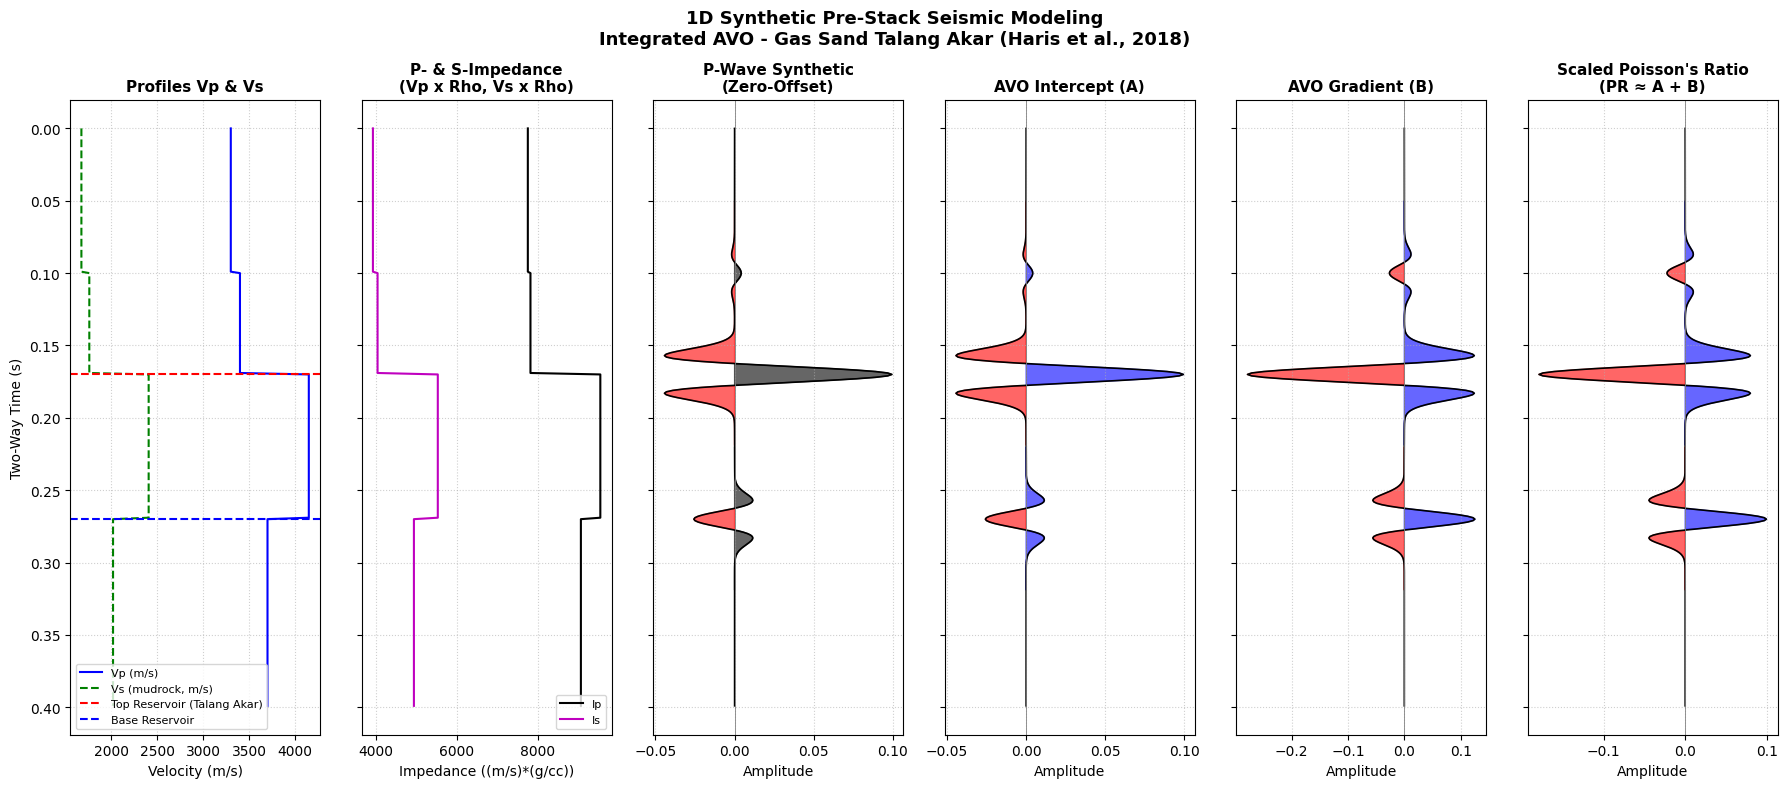

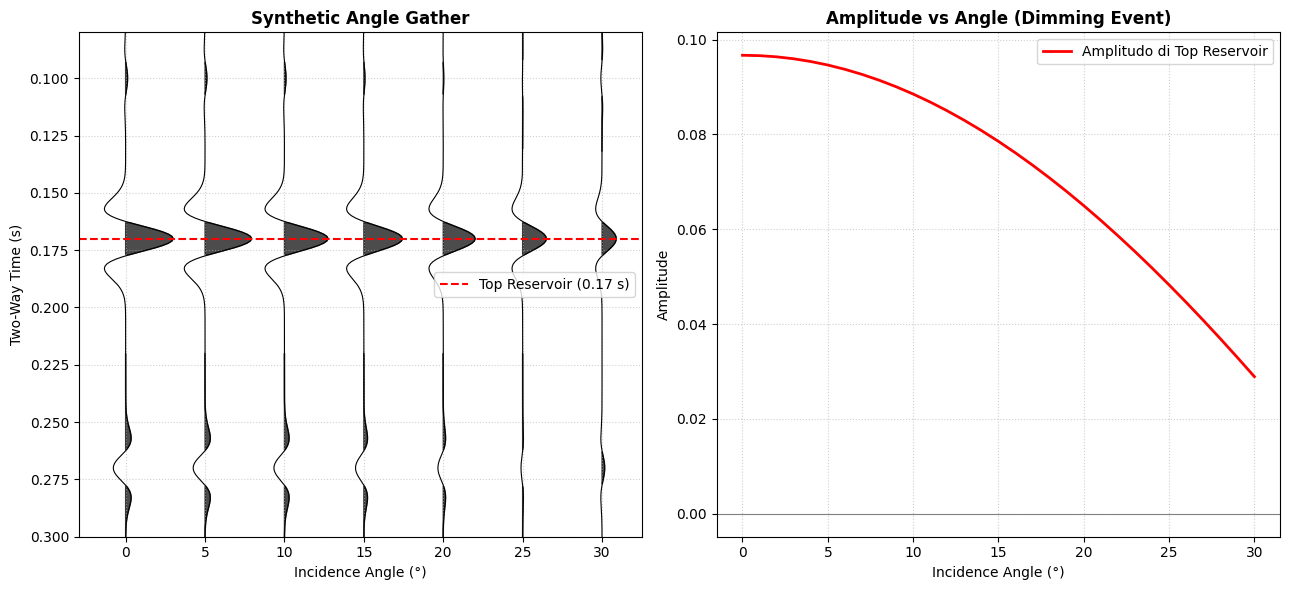

Top reservoir : Intercept A = +0.0993 | Gradient B = -0.2785 | PR = -0.1792
Reservoir     : Ip = 9545 | Is = 5532 | Vp/Vs = 1.73 | rho = 2.30 g/cc
Overburden    : Ip = 7820 | Is = 4045 | Vp/Vs = 1.93
Amplitudo top reservoir: 0° = 0.0967 -> 30° = 0.0289
Klasifikasi AVO: A>0 dan B<0  -> Type I (Rutherford-Williams) / Type -1 non-conforming sand (Young-Lo Piccolo)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. PARAMETER MODEL & KISI (GRID 1D)
# ==========================================
dt = 0.001            # Sampling time (detik)
t_max = 0.4           # Durasi simulasi (detik)
time = np.arange(0, t_max, dt)
nt = len(time)

# ==========================================
# 2. DEFINISI LOG LITHOLOGY & FISIKA BATUAN
# (Berdasarkan Formasi Talang Akar, Cekungan Sumatera Selatan - Haris dkk., 2018)
# Vp diberikan, Vs diturunkan dari Castagna's Mudrock Line:
#   Vs = 0.8621*Vp - 1172.4   (m/s)
# ==========================================
def mudrock(vp):
    return 0.8621 * vp - 1172.4

vp, rho = np.zeros(nt), np.zeros(nt)

# Lapisan 1: Shale atas (0 - 0.10 s)
vp[:100] = 3300.0;     rho[:100] = 2.35
# Lapisan 2: Shale penutup / overlying layer (0.10 - 0.17 s)
vp[100:170] = 3400.0;  rho[100:170] = 2.30
# Lapisan 3: Gas sandstone Talang Akar (0.17 - 0.27 s) -> target zone
vp[170:270] = 4150.0;  rho[170:270] = 2.30
# Lapisan 4: Shale bawah (0.27 - 0.40 s)
vp[270:] = 3700.0;     rho[270:] = 2.45

vs = mudrock(vp)

# Impedansi
Ip = vp * rho           # P-impedance
Is = vs * rho           # S-impedance
vpvs = vp / vs

# Lambda-Mu-Rho (Goodway dkk., 1997): LambdaRho = Ip^2 - 2 Is^2 ; MuRho = Is^2
lambda_rho = (Ip**2 - 2 * Is**2) / 1e6   # (GPa*g/cc)
mu_rho = (Is**2) / 1e6

# ==========================================
# 3. AKI-RICHARDS (PENDEKATAN SHUEY 2-SUKU) PER ANTARMUKA
#    R(theta) = A + B sin^2(theta)
#    A = 0.5*(dVp/Vp + dRho/Rho)
#    B = 0.5*dVp/Vp - 2*(Vs/Vp)^2 * (dRho/Rho + 2*dVs/Vs)
# ==========================================
angles = np.arange(0, 31, 5)                  # sudut datang (derajat)
th = np.radians(angles)

def avg(x):  return 0.5 * (x[1:] + x[:-1])
def diff(x): return x[1:] - x[:-1]

dvp, dvs, drho = diff(vp), diff(vs), diff(rho)
vp_m, vs_m, rho_m = avg(vp), avg(vs), avg(rho)

A = np.zeros(nt); B = np.zeros(nt)
A[:-1] = 0.5 * (dvp / vp_m + drho / rho_m)
B[:-1] = 0.5 * dvp / vp_m - 2 * (vs_m / vp_m)**2 * (drho / rho_m + 2 * dvs / vs_m)

# Scaled Poisson's ratio change (pendekatan Verm & Hilterman: PR ~ A + B)
PR = A + B

# ==========================================
# 4. RICKER WAVELET & KONVOLUSI (FORWARD MODELING PRE-STACK)
# ==========================================
f_dom = 30.0
t_wav = np.arange(-0.05, 0.05, dt)
wavelet = (1.0 - 2.0 * (np.pi * f_dom * t_wav)**2) * np.exp(-(np.pi * f_dom * t_wav)**2)

R_theta = np.array([A + B * np.sin(t)**2 for t in th])           # (n_angle, nt)
gather = np.array([np.convolve(r, wavelet, mode='same') for r in R_theta])

zero_offset = gather[0]
A_sec  = np.convolve(A,  wavelet, mode='same')
B_sec  = np.convolve(B,  wavelet, mode='same')
PR_sec = np.convolve(PR, wavelet, mode='same')

# ==========================================
# 5. VISUALISASI HASIL (PLOT PAPER-READY)
# ==========================================
def wiggle(ax, tr, color_pos, color_neg):
    ax.plot(tr, time, 'k-', linewidth=1.2)
    ax.fill_betweenx(time, 0, tr, where=(tr > 0), color=color_pos, alpha=0.6)
    ax.fill_betweenx(time, 0, tr, where=(tr < 0), color=color_neg, alpha=0.6)
    ax.axvline(0, color='gray', lw=0.6)
    ax.grid(True, linestyle=':', alpha=0.6)

fig, ax = plt.subplots(1, 6, figsize=(18, 8), sharey=True)

ax[0].plot(vp, time, 'b-', label='Vp (m/s)', linewidth=1.5)
ax[0].plot(vs, time, 'g--', label='Vs (mudrock, m/s)', linewidth=1.5)
ax[0].set_title("Profiles Vp & Vs", fontsize=11, fontweight='bold')
ax[0].set_ylabel("Two-Way Time (s)", fontsize=10)
ax[0].set_xlabel("Velocity (m/s)", fontsize=10)
ax[0].axhline(0.17, color='r', linestyle='--', label='Top Reservoir (Talang Akar)')
ax[0].axhline(0.27, color='b', linestyle='--', label='Base Reservoir')
ax[0].legend(loc='lower left', fontsize=8)
ax[0].grid(True, linestyle=':', alpha=0.6)
ax[0].invert_yaxis()

ax[1].plot(Ip, time, 'k-', label='Ip', linewidth=1.5)
ax[1].plot(Is, time, 'm-', label='Is', linewidth=1.5)
ax[1].set_title("P- & S-Impedance\n(Vp x Rho, Vs x Rho)", fontsize=11, fontweight='bold')
ax[1].set_xlabel("Impedance ((m/s)*(g/cc))", fontsize=10)
ax[1].legend(loc='lower right', fontsize=8)
ax[1].grid(True, linestyle=':', alpha=0.6)

wiggle(ax[2], zero_offset, 'black', 'red')
ax[2].set_title("P-Wave Synthetic\n(Zero-Offset)", fontsize=11, fontweight='bold')
ax[2].set_xlabel("Amplitude", fontsize=10)

wiggle(ax[3], A_sec, 'blue', 'red')
ax[3].set_title("AVO Intercept (A)", fontsize=11, fontweight='bold')
ax[3].set_xlabel("Amplitude", fontsize=10)

wiggle(ax[4], B_sec, 'blue', 'red')
ax[4].set_title("AVO Gradient (B)", fontsize=11, fontweight='bold')
ax[4].set_xlabel("Amplitude", fontsize=10)

wiggle(ax[5], PR_sec, 'blue', 'red')
ax[5].set_title("Scaled Poisson's Ratio\n(PR ≈ A + B)", fontsize=11, fontweight='bold')
ax[5].set_xlabel("Amplitude", fontsize=10)

plt.suptitle("1D Synthetic Pre-Stack Seismic Modeling\nIntegrated AVO - Gas Sand Talang Akar (Haris et al., 2018)",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# --- Figure 2: Angle gather & kurva amplitudo vs sudut di top reservoir ---
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
sp = 0.6 / np.abs(gather).max()
for k, a in enumerate(angles):
    tr = gather[k] * sp * 5 + a
    ax[0].plot(tr, time, 'k-', lw=0.8)
    ax[0].fill_betweenx(time, a, tr, where=(tr > a), color='black', alpha=0.7)
ax[0].axhline(0.17, color='r', ls='--', label='Top Reservoir (0.17 s)')
ax[0].set_ylim(0.30, 0.08)
ax[0].set_title("Synthetic Angle Gather", fontweight='bold')
ax[0].set_xlabel("Incidence Angle (°)"); ax[0].set_ylabel("Two-Way Time (s)")
ax[0].legend(); ax[0].grid(True, ls=':', alpha=0.6)

ang_f = np.arange(0, 31, 1); th_f = np.radians(ang_f)
i_top = 169                               # indeks antarmuka top reservoir
amp_top = np.array([ (np.convolve(A + B*np.sin(t)**2, wavelet, 'same'))[i_top] for t in th_f ])
ax[1].plot(ang_f, amp_top, 'r-', lw=2, label='Amplitudo di Top Reservoir')
ax[1].axhline(0, color='gray', lw=0.8)
ax[1].set_title("Amplitude vs Angle (Dimming Event)", fontweight='bold')
ax[1].set_xlabel("Incidence Angle (°)"); ax[1].set_ylabel("Amplitude")
ax[1].legend(); ax[1].grid(True, ls=':', alpha=0.6)
plt.tight_layout(); plt.show()

# --- Ringkasan numerik ---
i = 169
print(f"Top reservoir : Intercept A = {A[i]:+.4f} | Gradient B = {B[i]:+.4f} | PR = {PR[i]:+.4f}")
print(f"Reservoir     : Ip = {Ip[200]:.0f} | Is = {Is[200]:.0f} | Vp/Vs = {vpvs[200]:.2f} | rho = {rho[200]:.2f} g/cc")
print(f"Overburden    : Ip = {Ip[120]:.0f} | Is = {Is[120]:.0f} | Vp/Vs = {vpvs[120]:.2f}")
print(f"Amplitudo top reservoir: 0° = {amp_top[0]:.4f} -> 30° = {amp_top[-1]:.4f}")
print("Klasifikasi AVO: A>0 dan B<0  -> Type I (Rutherford-Williams) / Type -1 non-conforming sand (Young-Lo Piccolo)")


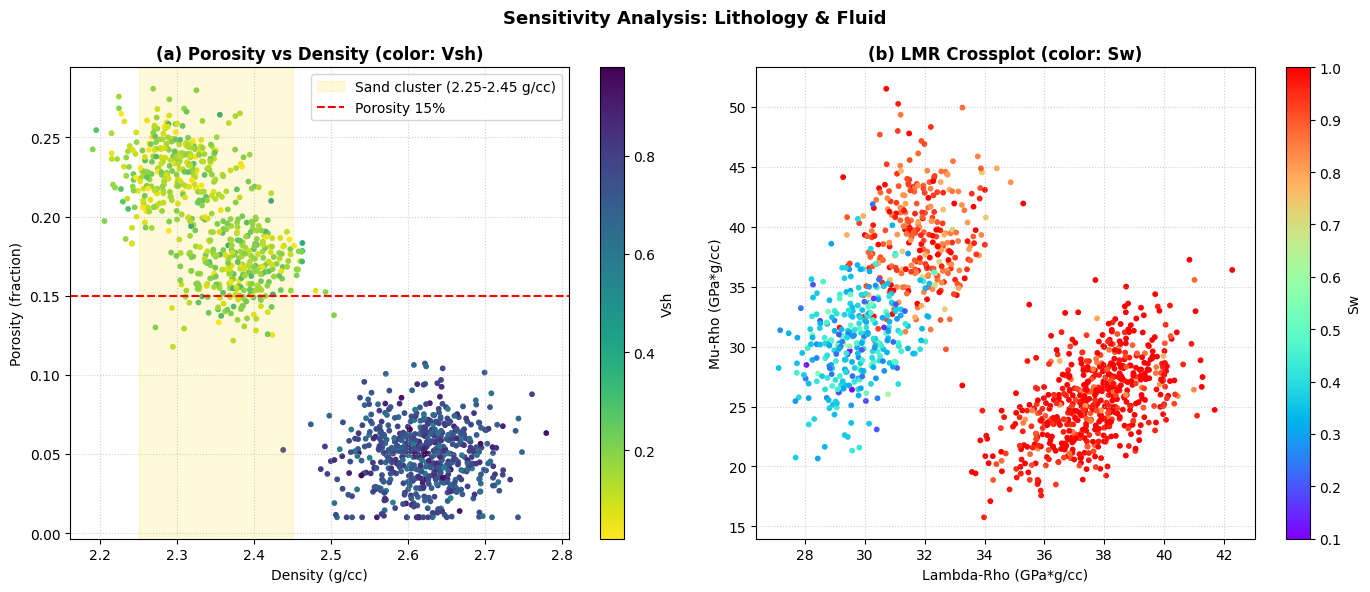

Rata-rata LambdaRho  gas sand: 29.7 | water sand: 31.8 | shale: 37.7
Rata-rata MuRho      gas sand: 30.5 | water sand: 39.2 | shale: 25.6


In [2]:
# ==========================================
# 6. ANALISIS SENSITIVITAS PETROFISIKA (CROSSPLOT)
# Log sintetis = model blok + noise Gaussian (representasi variasi log sumur)
# ==========================================
rng = np.random.default_rng(42)
n = 600
# Tiga populasi batuan: shale, sandstone basah (Sw tinggi), gas sandstone (Sw rendah)
def pop(n, vp0, rho0, vsh0, phi0, sw0, sd):
    vp_ = rng.normal(vp0, sd[0], n); rho_ = rng.normal(rho0, sd[1], n)
    vsh_ = np.clip(rng.normal(vsh0, 0.08, n), 0.02, 0.98)
    phi_ = np.clip(rng.normal(phi0, 0.02, n), 0.01, 0.35)
    sw_ = np.clip(rng.normal(sw0, 0.08, n), 0.1, 1.0)
    return vp_, rho_, vsh_, phi_, sw_

shale = pop(n,   3600, 2.62, 0.75, 0.05, 1.00, (150, 0.05))
wet   = pop(n//2, 4400, 2.38, 0.20, 0.17, 0.90, (150, 0.04))
gas   = pop(n//2, 4150, 2.30, 0.15, 0.23, 0.35, (150, 0.04))
vp_l, rho_l, vsh_l, phi_l, sw_l = [np.concatenate(z) for z in zip(shale, wet, gas)]
vs_l = mudrock(vp_l)
ip_l, is_l = vp_l * rho_l, vs_l * rho_l
lr_l = (ip_l**2 - 2 * is_l**2) / 1e6
mr_l = (is_l**2) / 1e6

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sc = ax[0].scatter(rho_l, phi_l, c=vsh_l, cmap='viridis_r', s=10)
ax[0].axvspan(2.25, 2.45, color='gold', alpha=0.15, label='Sand cluster (2.25-2.45 g/cc)')
ax[0].axhline(0.15, color='r', ls='--', label='Porosity 15%')
ax[0].set_xlabel("Density (g/cc)"); ax[0].set_ylabel("Porosity (fraction)")
ax[0].set_title("(a) Porosity vs Density (color: Vsh)", fontweight='bold')
plt.colorbar(sc, ax=ax[0]).set_label("Vsh")
ax[0].legend(loc='upper right'); ax[0].grid(True, ls=':', alpha=0.6)

sc = ax[1].scatter(lr_l, mr_l, c=sw_l, cmap='rainbow', s=10)
ax[1].set_xlabel("Lambda-Rho (GPa*g/cc)"); ax[1].set_ylabel("Mu-Rho (GPa*g/cc)")
ax[1].set_title("(b) LMR Crossplot (color: Sw)", fontweight='bold')
plt.colorbar(sc, ax=ax[1]).set_label("Sw")
ax[1].grid(True, ls=':', alpha=0.6)
plt.suptitle("Sensitivity Analysis: Lithology & Fluid", fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

print(f"Rata-rata LambdaRho  gas sand: {lr_l[-n//2:].mean():.1f} | water sand: {lr_l[n:n+n//2].mean():.1f} | shale: {lr_l[:n].mean():.1f}")
print(f"Rata-rata MuRho      gas sand: {mr_l[-n//2:].mean():.1f} | water sand: {mr_l[n:n+n//2].mean():.1f} | shale: {mr_l[:n].mean():.1f}")


## **Analisis Hasil Pemodelan Sintetik 1D pada Studi Kasus Reservoar Gas Formasi Talang Akar**
Pemodelan sintetik pre-stack 1D berbasis forward modeling berhasil direalisasikan untuk merepresentasikan respon reservoar gas Formasi Talang Akar pada jurnal Haris dkk. (2018). Pada panel profil kecepatan dan impedansi, zona reservoar (0.17 s hingga 0.27 s) memiliki P-impedance sekitar $9545\ (m/s)(g/cc)$ dan S-impedance sekitar $5532\ (m/s)(g/cc)$, tepat berada dalam rentang yang dilaporkan jurnal ($9000$-$10000$ dan $5000$-$5600$). Rasio $V_p/V_s$ turun dari $1.93$ pada lapisan penutup menjadi $1.73$ pada reservoar, yang konsisten dengan kehadiran batupasir bersaturasi gas. Perlu dicatat bahwa jurnal tidak konsisten dalam menyebut posisi impedansi reservoar (abstrak menyebut sedikit lebih tinggi dari lapisan di atasnya, sedangkan bagian hasil menyebut lebih rendah). Model ini mengikuti interpretasi AVO jurnal, yaitu Intercept positif, sehingga impedansi reservoar lebih tinggi daripada serpih penutup.

Pada penampang zero-offset, batas atas reservoar menghasilkan peak positif yang jelas pada $0.17\ s$ dengan amplitudo sekitar $0.097$. Atribut AVO pada batas tersebut bernilai $A = +0.099$ dan $B = -0.279$. Kombinasi Intercept positif dan Gradient negatif ini mengklasifikasikan reservoar sebagai **Type I** (Rutherford-Williams) atau **Type -1 non-conforming sand** (Young-Lo Piccolo), sesuai kesimpulan jurnal. Hal ini diperkuat oleh angle gather dan kurva amplitudo terhadap sudut: amplitudo menurun dari $0.097$ pada $0^\circ$ menjadi $0.029$ pada $30^\circ$ tanpa pembalikan polaritas, yaitu pola dimming event seperti pada FIGURE 3 jurnal.

Atribut turunan scaled Poisson's ratio ($PR \approx A + B$) bernilai negatif ($-0.179$) tepat di batas atas reservoar, sehingga muncul anomali trough yang jelas. Sesuai jurnal, nilai negatif ini diasosiasikan dengan keberadaan hidrokarbon gas. Pada crossplot sensitivitas, populasi gas sand (Sw rendah) memiliki rata-rata $\lambda\rho \approx 29.7$, lebih rendah daripada water sand ($31.8$) dan shale ($37.7$), sedangkan $\mu\rho$ membedakan litologi (shale $25.6$ vs sand $30.5$-$39.2$). Hal ini menunjukkan bahwa $\lambda\rho$ sensitif terhadap fluida dan $\mu\rho$ terhadap litologi, sehingga crossplot LMR dapat membatasi zona hidrokarbon.

Perlu diingat bahwa hasil ini merupakan model sintetik 1D dengan parameter yang dikalibrasi terhadap angka-angka pada jurnal, bukan hasil inversi data lapangan. Pendekatan Shuey dua suku hanya akurat untuk sudut kecil hingga menengah (dibatasi $30^\circ$ di sini), dan crossplot dibangun dari log sintetis ber-noise sehingga hanya bersifat ilustratif. Secara keseluruhan, integrasi analisis AVO, atribut Poisson, dan crossplot petrofisika terbukti efektif untuk mengidentifikasi reservoar gas yang kontras impedansinya rendah.
